In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('National Poll on Healthy Aging (NPHA).csv')
df

,Number of Doctors Visited,Age,Phyiscal Health,Mental Health,Dental Health,Employment,Stress Keeps Patient from Sleeping,Medication Keeps Patient from Sleeping,Pain Keeps Patient from Sleeping,Uknown Keeps Patient from Sleeping,Trouble Sleeping,Prescription Sleep Medication,Race,Gender
0,2,2,4,3,3,3,0,0,0,0,2,3,1,1
1,2,2,5,4,3,3,1,0,1,0,2,3,1,1
2,2,2,2,2,1,3,0,0,0,0,3,3,1,1
3,3,2,4,3,2,3,0,0,1,1,2,3,1,1
4,2,2,1,1,1,3,0,0,0,0,3,3,1,1
5,3,2,3,3,2,3,0,1,0,1,2,2,1,1
6,2,2,2,2,2,3,0,0,0,1,3,3,1,1
7,3,2,3,2,6,3,0,0,0,1,2,3,1,1
8,2,2,3,3,3,3,0,0,0,0,3,3,1,1
9,2,2,2,4,2,3,0,1,0,0,2,3,1,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 14 columns):
 #   Column                                  Non-Null Count  Dtype
---  ------                                  --------------  -----
 0   Number of Doctors Visited               45 non-null     int64
 1   Age                                     45 non-null     int64
 2   Phyiscal Health                         45 non-null     int64
 3   Mental Health                           45 non-null     int64
 4   Dental Health                           45 non-null     int64
 5   Employment                              45 non-null     int64
 6   Stress Keeps Patient from Sleeping      45 non-null     int64
 7   Medication Keeps Patient from Sleeping  45 non-null     int64
 8   Pain Keeps Patient from Sleeping        45 non-null     int64
 9   Uknown Keeps Patient from Sleeping      45 non-null     int64
 10  Trouble Sleeping                        45 non-null     int64
 11  Prescription Sleep Me

In [5]:
target_column = df.columns[-1]
X = df.drop(target_column, axis=1)
y = df[target_column]

In [6]:
X_encoded = pd.get_dummies(X)

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.3, random_state=42)

In [16]:
model = DecisionTreeClassifier(criterion='entropy', random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [17]:
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.7142857142857143


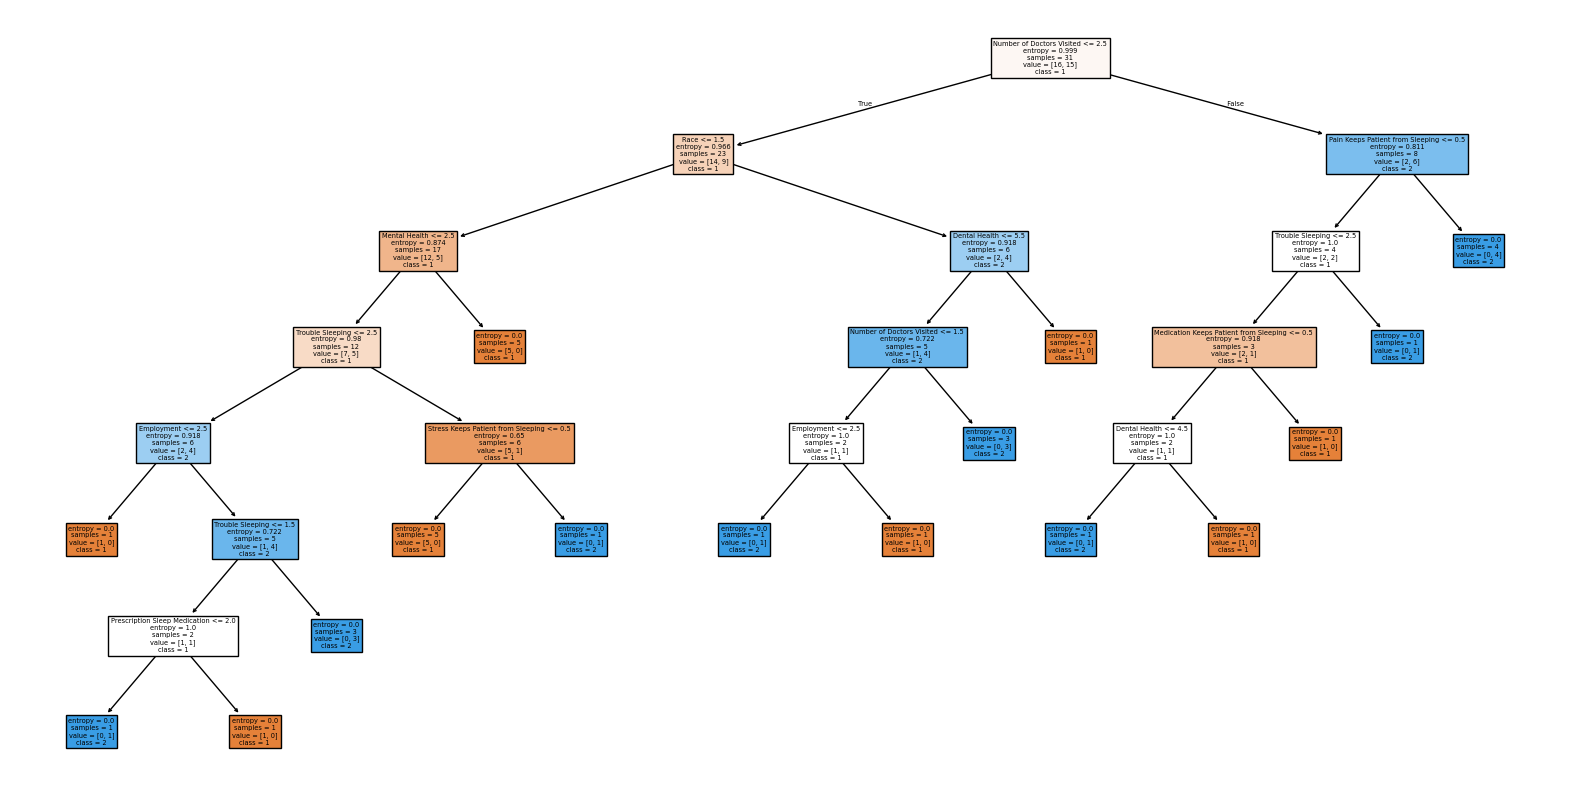

In [18]:
plt.figure(figsize=(20,10))
plot_tree(model, feature_names=X_encoded.columns, class_names=[str(cls) for cls in model.classes_], filled=True)
plt.show()

In [20]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[3 3]
 [1 7]]
